# pyspan, TA: compare scans, reject, review t0

Example on 250709, scans `s40` and `s44`: compare the scans, reject bad data, review t0 points.

Principle: each interactive tool is preceded by a **decisions** cell holding the literal that the
tool's "Done" button prints (paste it there), and followed by a plain data step that uses the
literal, without the widget. "Run all" therefore reproduces the result without clicking.

Needs `%matplotlib widget` (JupyterLab or VS Code, with `ipympl`).

In [2]:
%matplotlib widget
from pathlib import Path

import numpy as np
from numpy.polynomial import Polynomial

from edyx.io import read_dat, stack_traces
from edyx.plot import plot_maps
from edyx.tana import avg_scans, shift_trace, subtract_pre_t0
from edyx.units import nm2ev
from pyspan import Overlay, ScanInspector, T0Picker
from pyspan.decisions import above_threshold, rejection_mask, rmsd_vs_median

## Parameters and read

In [3]:
data_dir = Path("../../edyx/examples/data")  # edyx example data, see its README.md
fnames = ["s40.dat", "s44.dat"]
t_pre = -0.7  # ps: delays t < t_pre are before time zero

In [4]:
t, wl, stack = stack_traces([read_dat(data_dir / f) for f in fnames])
stack = np.ma.masked_invalid(stack)  # axes: (file, wl, delay)
stack.shape

(2, 512, 351)

## Compare the scans

In [5]:
Overlay.from_stack(t, wl, stack, labels=fnames, mode="kinetics").show()

## Reject data

RMSD of each scan against the median of the scans. With 2 files the median is the mean, so both
files get the same RMSD and the threshold cannot single out one file.

In [6]:
rmsd = rmsd_vs_median(stack, axis=0)

In [7]:
# Paste the output of "Done" here. Format: (file, wl, t) indices, None = all,
# (start, stop) = range, stop excluded. E.g. [(1, None, (250, None))]
rejections = []
threshold = None  # None: no threshold

In [8]:
insp = ScanInspector(t, wl, stack, labels=fnames, rejections=rejections,
                     rmsd=rmsd, threshold=threshold)
insp.show()

In [11]:
insp.mask

array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]],
      shape=(2, 512, 351))

In [12]:
mask = rejection_mask(stack.shape, rejections)
if threshold is not None:
    mask |= rejection_mask(stack.shape, above_threshold(rmsd, threshold))
data = np.ma.masked_array(stack, mask=mask)  # the NaN masked at load stay masked

## Average and subtract the pre-t0 spectrum

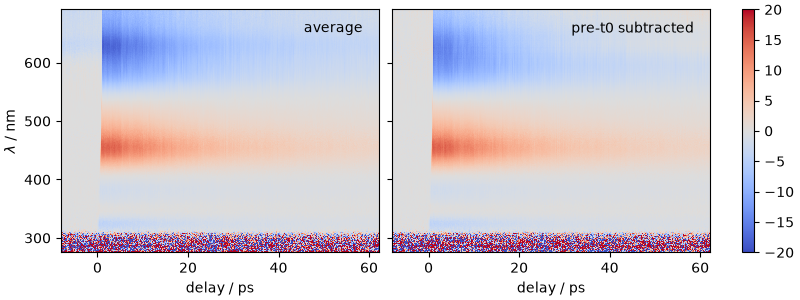

In [14]:
avg = avg_scans(data)
avg_sub = subtract_pre_t0(t, avg, t_pre)

fig, axes = plot_maps(t, wl, [avg, avg_sub], titles=["average", "pre-t0 subtracted"], vmin=-20, vmax=20)

In [18]:
help(Overlay)

Help on class Overlay in module pyspan.overlay:

class Overlay(builtins.object)
 |  Overlay(traces, mode='spectra', value=None, ylim=None, ylabel=None)
 |
 |  Overlay of several datasets, with a slider on delay or wavelength.
 |
 |  Parameters
 |  ----------
 |  traces : dict
 |      `{label: (t, wl, s)}`, with `s` shaped (W, T). Datasets may have different
 |      axes.
 |  mode : {"spectra", "kinetics"}
 |      "spectra": x = wl, slider on delay. "kinetics": x = t, slider on wavelength.
 |  value : float, optional
 |      Initial delay or wavelength (snapped to the grid). Default: first grid value.
 |  ylim : (float, float), optional
 |      Y limits. Default: 1st to 99th percentile of all data, plus a 5% margin.
 |  ylabel : str, optional
 |      Y-axis label.
 |
 |  Attributes
 |  ----------
 |  value : float
 |      Current delay (spectra) or wavelength (kinetics), a value of `grid`.
 |  grid : np.ndarray
 |      Sorted union of the slider axes of all datasets.
 |  fig, ax : matpl

In [19]:
Overlay(
    {"avg": (t, wl, avg),
     "t0 subtracted": (t, wl, avg_sub)
     },
     mode="kinetics"
     ).show()

## Review the t0 points

The t0 points are normally picked on a reference measurement (here `s20`-`s27`, stored in
`s2027_t0corr.npz`). They are opened here on the s40+s44 average only to show the review.

In [20]:
t0_points = np.load(data_dir / "s2027_t0corr.npz")["t0_meas"]  # or paste the output of "Done"

In [24]:
picker = T0Picker(t, wl, avg_sub, points=t0_points, tlim=(-2, 2), clim=(-20, 20))
picker.show()

## Fit and shift

Plain numpy, the fit is the user's choice. Points are `(wl, t0)`.

In [ ]:
coef = Polynomial.fit(nm2ev(t0_points[:, 0]), t0_points[:, 1], 3).convert().coef  # choice: cubic in eV
t0 = Polynomial(coef)(nm2ev(wl))

In [ ]:
# check: with the stored points, the lab's coefficients are recovered
assert np.allclose(coef, np.load(data_dir / "s2027_t0corr.npz")["pol_coeff"])

In [ ]:
t_c, shifted = shift_trace(t, avg_sub, t0)

fig, axes = plot_maps(t, wl, [avg_sub], titles=["before"])
axes[0, 0].plot(t0, wl, color="k", lw=0.5)
axes[0, 0].set_xlim(-2, 2)

fig, axes = plot_maps(t_c, wl, [shifted], titles=["after"])
axes[0, 0].axvline(0, color="k", lw=0.5)
axes[0, 0].set_xlim(-2, 2)